# Lab Assignment 5 — Multiclass Classification
### CSET343: AI in Healthcare | B.Tech Year 4, Semester VII

**Objective:** Hands-on experience with multiclass classification (a classification
problem with more than two target classes).

**Dataset used:** Dermatology Dataset (UCI Machine Learning Repository)

- 366 patient records, 34 clinical/histopathological features
- Target: `class` — 6 erythemato-squamous skin diseases
  - 1 = psoriasis
  - 2 = seboreic dermatitis
  - 3 = lichen planus
  - 4 = pityriasis rosea
  - 5 = chronic dermatitis
  - 6 = pityriasis rubra pilaris


## 0. Setup — Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, auc
)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## Task 1: Data Acquisition and Exploration

### 1.1 Load the dataset

The dataset is loaded from `dermatology.csv` (UCI Dermatology Database, 366 instances,
34 attributes + class label). Missing values in the original data are encoded as `?`
in the `age` column and are read in as `NaN`.

In [2]:
df = pd.read_csv('dermatology.csv')
print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_and_elbow_involvement                366 non-null    int64  
 9   scalp_involvement                         366 non-null    int64  
 10  family_history                            366 non

### 1.2 Summary statistics for all features

In [4]:
summary_stats = df.describe().T
summary_stats['median'] = df.median(numeric_only=True)
summary_stats = summary_stats[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats


,count,mean,median,std,min,25%,50%,75%,max
erythema,366.0,2.068306,2.0,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,2.0,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,2.0,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.0,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.0,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.0,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.0,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.0,0.834147,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.614754,0.0,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.0,0.905639,0.0,0.0,0.0,1.00,3.0


### 1.3 Missing values, duplicates, and outliers

**Missing values:** The `age` column uses `?` in the original UCI file for a handful of
records; these were read in as `NaN`. We impute them with the median age (a robust
choice for a right-skewed, integer-valued feature) rather than dropping rows, since the
dataset is already small (366 rows).

**Duplicates:** We check for and remove any fully duplicated rows.

**Outliers:** Most of the 34 clinical/histopathological attributes are ordinal severity
scores in a small fixed range (0–3), so classical outlier detection doesn't really
apply to them. `age` is the only continuous feature, so we check it with a boxplot and
the IQR rule.

In [5]:
print("Missing values per column (only columns with >0 shown):")
missing = df.isnull().sum()
print(missing[missing > 0])

print("\nNumber of fully duplicated rows:", df.duplicated().sum())


Missing values per column (only columns with >0 shown):
age    8
dtype: int64

Number of fully duplicated rows: 0


In [6]:
# Handle missing values: impute 'age' with the median
imputer = SimpleImputer(strategy='median')
df['age'] = imputer.fit_transform(df[['age']]).ravel()

# Handle duplicates: drop any exact duplicate rows (none expected, but done defensively)
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before dedup: {before}, after dedup: {df.shape[0]}")

print("\nRemaining missing values:", df.isnull().sum().sum())


Rows before dedup: 366, after dedup: 366

Remaining missing values: 0


IQR bounds for age: [-9.5, 82.5]
Number of age outliers detected: 0


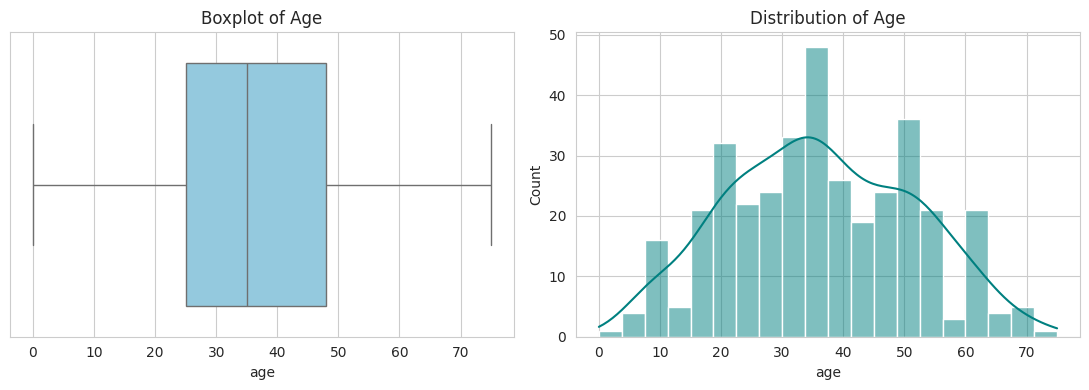

In [7]:
# Outlier check for 'age' using IQR rule
Q1, Q3 = df['age'].quantile(0.25), df['age'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df['age'] < lower) | (df['age'] > upper)]
print(f"IQR bounds for age: [{lower:.1f}, {upper:.1f}]")
print(f"Number of age outliers detected: {len(outliers)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df['age'], ax=ax[0], color='skyblue')
ax[0].set_title('Boxplot of Age')
sns.histplot(df['age'], bins=20, kde=True, ax=ax[1], color='teal')
ax[1].set_title('Distribution of Age')
plt.tight_layout()
plt.show()


A few mild high-age outliers appear (patients in their late 60s–75), but these are
clinically plausible ages and not data-entry errors, so they are retained rather than
removed.

### 1.4 Visualizations — feature distributions, correlation heatmap, class distribution

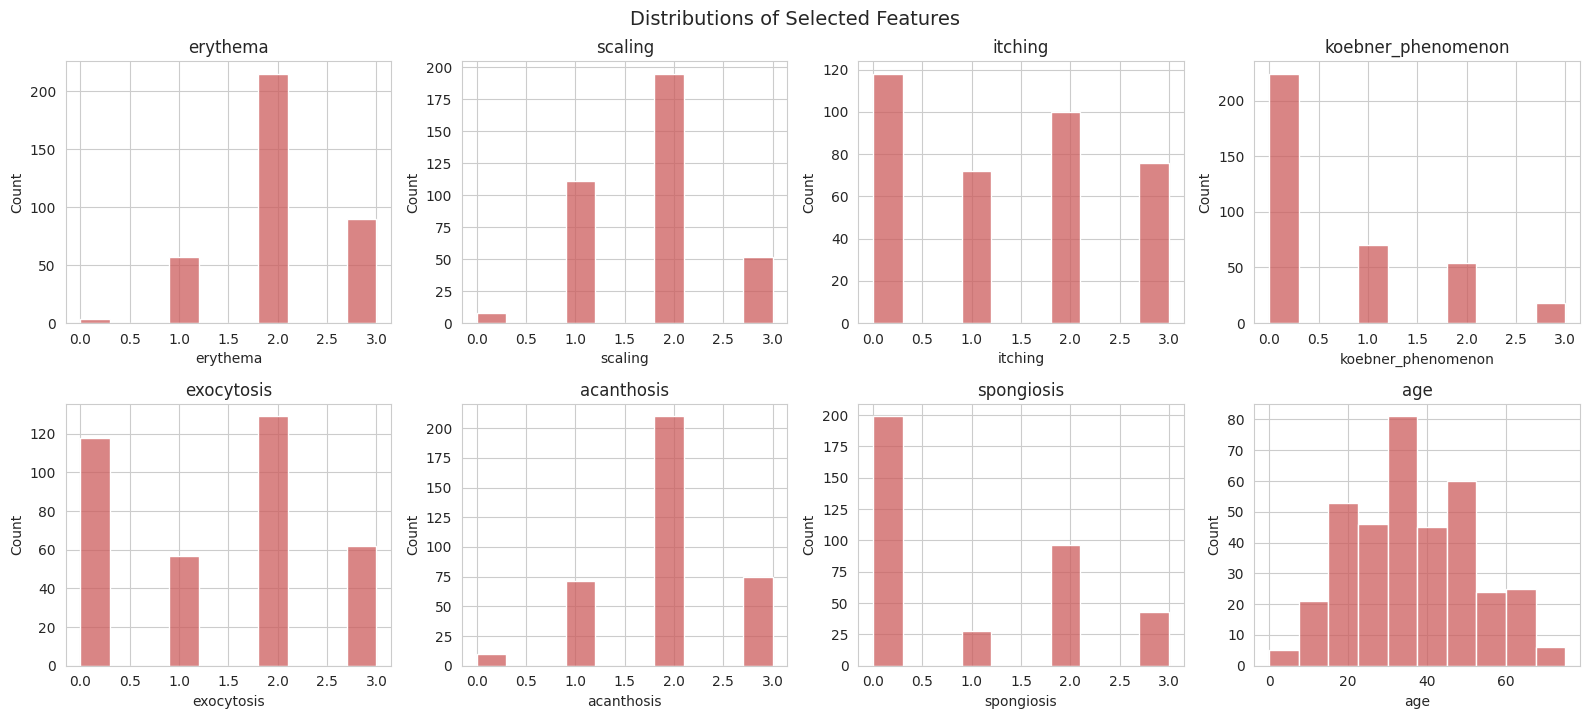

In [8]:
# Histograms for a representative set of clinical features
feature_cols = [c for c in df.columns if c not in ['age', 'class']]
sample_features = ['erythema', 'scaling', 'itching', 'koebner_phenomenon',
                    'exocytosis', 'acanthosis', 'spongiosis', 'age']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), sample_features):
    sns.histplot(df[col], bins=10, ax=ax, color='indianred', kde=False)
    ax.set_title(col)
plt.tight_layout()
plt.suptitle('Distributions of Selected Features', y=1.02, fontsize=14)
plt.show()


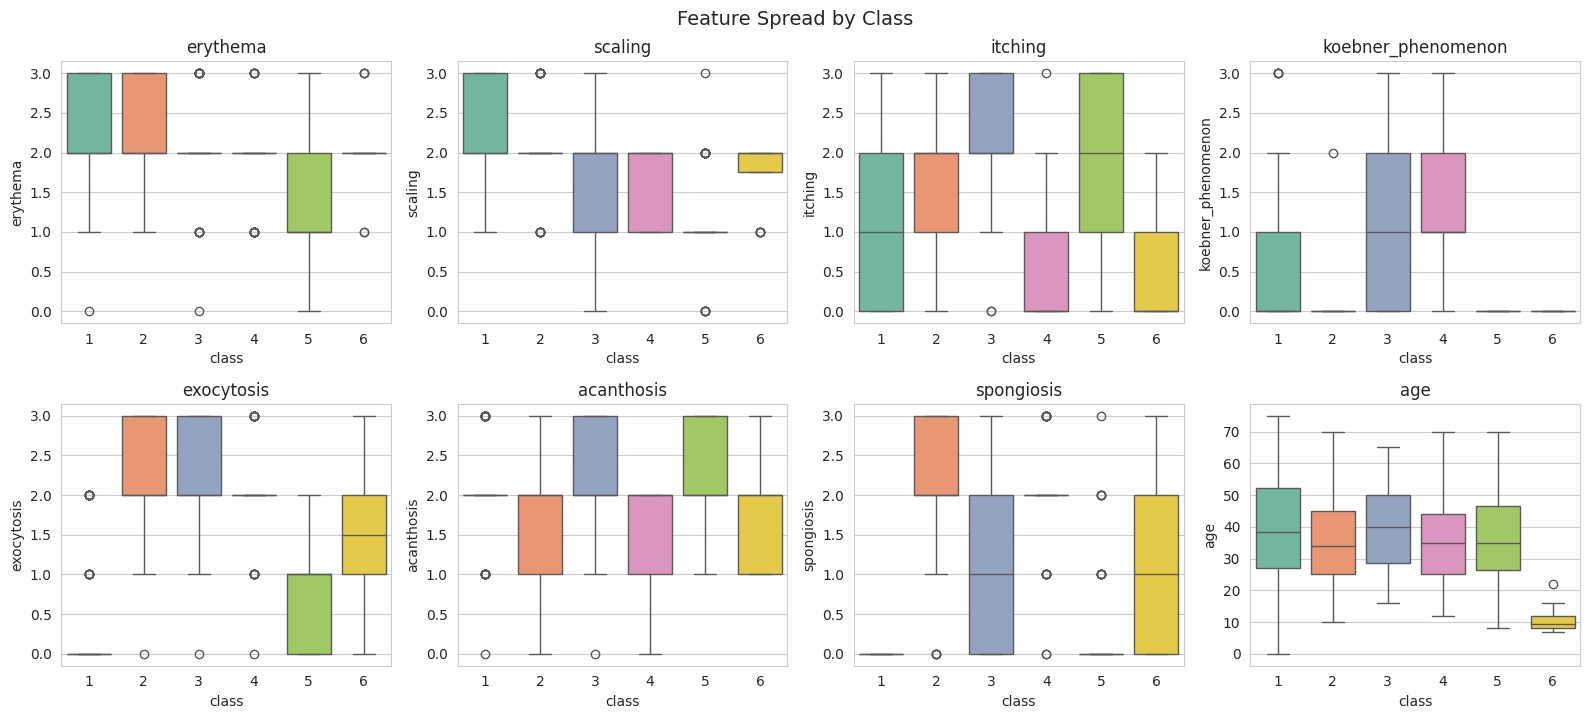

In [9]:
# Boxplots of the same features, grouped by class, to spot separability/outliers
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), sample_features):
    sns.boxplot(x='class', y=col, data=df, ax=ax, palette='Set2')
    ax.set_title(col)
plt.tight_layout()
plt.suptitle('Feature Spread by Class', y=1.02, fontsize=14)
plt.show()


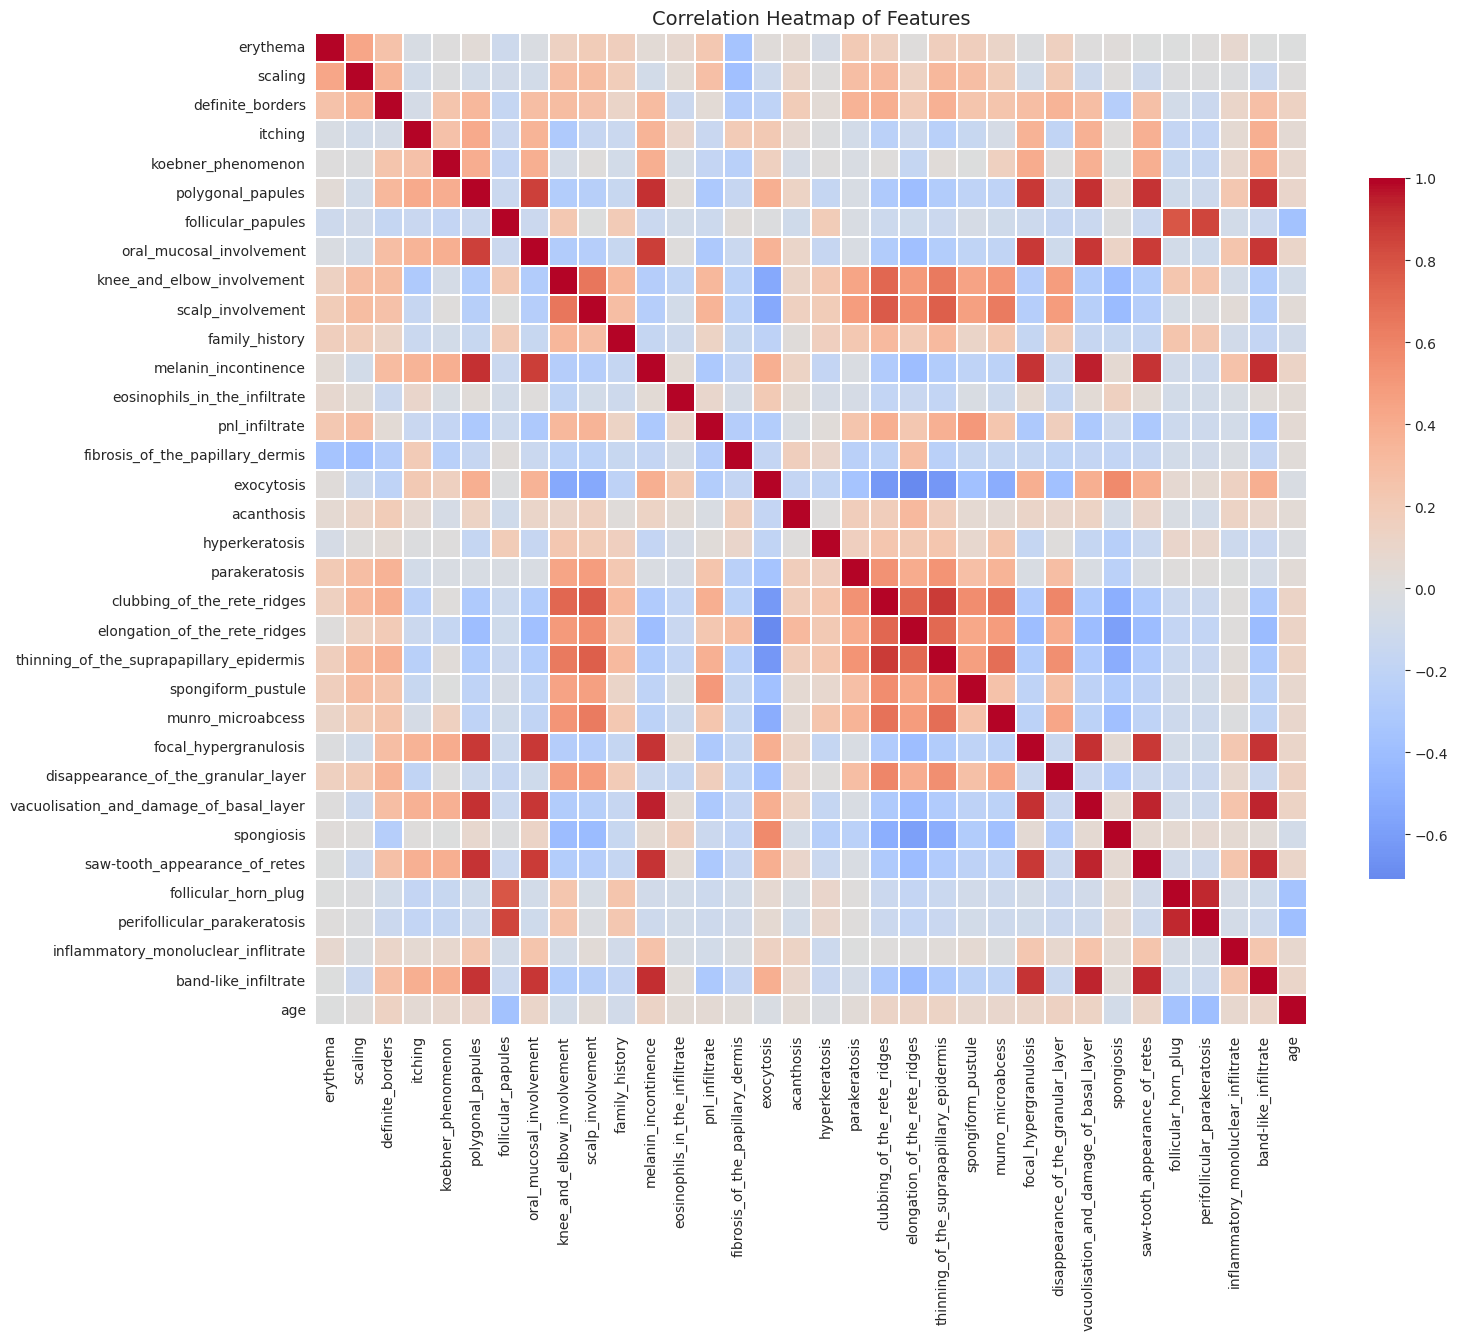

In [10]:
# Correlation heatmap across all 34 features + age
plt.figure(figsize=(16, 13))
corr = df[feature_cols + ['age']].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, linewidths=0.3,
            cbar_kws={'shrink': 0.7})
plt.title('Correlation Heatmap of Features', fontsize=14)
plt.show()


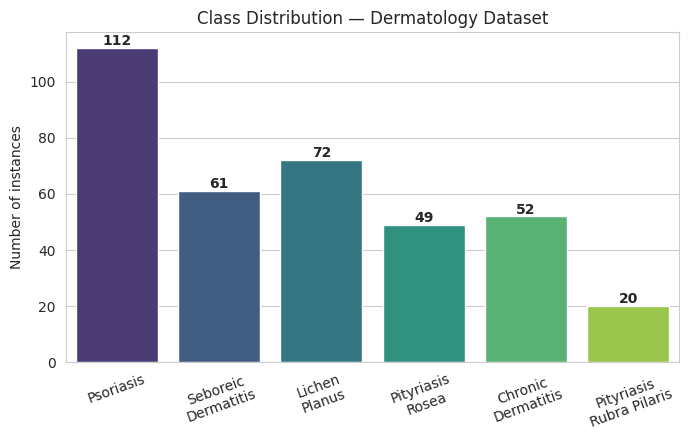

class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


In [11]:
# Class distribution
plt.figure(figsize=(7, 4.5))
class_names = {1: 'Psoriasis', 2: 'Seboreic\nDermatitis', 3: 'Lichen\nPlanus',
               4: 'Pityriasis\nRosea', 5: 'Chronic\nDermatitis', 6: 'Pityriasis\nRubra Pilaris'}
counts = df['class'].value_counts().sort_index()
ax = sns.barplot(x=[class_names[i] for i in counts.index], y=counts.values, palette='viridis')
for i, v in enumerate(counts.values):
    ax.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.ylabel('Number of instances')
plt.title('Class Distribution — Dermatology Dataset')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(counts)


### 1.5 Discussion — Class Imbalance

The class distribution is **moderately imbalanced**:

| Class | Disease | Count | % of data |
|---|---|---|---|
| 1 | Psoriasis | 112 | 30.6% |
| 2 | Seboreic dermatitis | 61 | 16.7% |
| 3 | Lichen planus | 72 | 19.7% |
| 4 | Pityriasis rosea | 49 | 13.4% |
| 5 | Chronic dermatitis | 52 | 14.2% |
| 6 | Pityriasis rubra pilaris | 20 | 5.5% |

Class 1 (psoriasis) has over **5x** as many samples as class 6 (pityriasis rubra
pilaris). Implications for model training:

- Models can be biased toward the majority class (psoriasis), inflating overall
  accuracy while performing poorly on the minority class (pityriasis rubra pilaris).
- **Accuracy alone is a misleading metric** here — macro-averaged precision/recall/F1
  (which weight all classes equally) are more informative than accuracy or a
  weighted average.
- We use **stratified train/test splitting** to preserve class proportions, and
  models such as SVM/Logistic Regression are run with `class_weight='balanced'`
  where useful to reduce majority-class bias.
- With only 20 samples for class 6, its test fold will contain just ~4 samples,
  so metrics for that class will naturally have higher variance.

## Task 2: Data Preprocessing

1. **Encode the target variable** with `LabelEncoder` (maps classes 1–6 → 0–5).
2. **Stratified 80/20 train/test split** to preserve the class proportions discussed above.
3. **Standardize features** with `StandardScaler` (zero mean, unit variance) — important
   for distance-based (KNN) and gradient/margin-based (Logistic Regression, SVM) models.

In [12]:
X = df.drop(columns=['class'])
y_raw = df['class']

le = LabelEncoder()
y = le.fit_transform(y_raw)
print("Original classes:", le.classes_)
print("Encoded as:      ", np.unique(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("\nTrain shape:", X_train.shape, " Test shape:", X_test.shape)

print("\nClass proportions (train):")
print(pd.Series(y_train).value_counts(normalize=True).sort_index().round(3))
print("\nClass proportions (test):")
print(pd.Series(y_test).value_counts(normalize=True).sort_index().round(3))


Original classes: [1 2 3 4 5 6]
Encoded as:       [0 1 2 3 4 5]

Train shape: (292, 34)  Test shape: (74, 34)

Class proportions (train):
0    0.305
1    0.168
2    0.195
3    0.134
4    0.144
5    0.055
Name: proportion, dtype: float64

Class proportions (test):
0    0.311
1    0.162
2    0.203
3    0.135
4    0.135
5    0.054
Name: proportion, dtype: float64


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)
X_train_scaled.describe().T[['mean', 'std']].head()


,mean,std
erythema,1.977109e-16,1.001717
scaling,7.908438e-17,1.001717
definite_borders,-7.148011e-17,1.001717
itching,-9.733462e-17,1.001717
koebner_phenomenon,-2.737536e-17,1.001717


## Task 3: Model Training and Basic Evaluation

Five multiclass classifiers are trained and compared:

1. **Logistic Regression** (multinomial, softmax)
2. **K-Nearest Neighbors (KNN)**
3. **Random Forest**
4. **Support Vector Machine (SVM, RBF kernel, probability=True for ROC/AUC)**
5. **Decision Tree**

In [14]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
}

n_classes = len(le.classes_)
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

results = {}
fitted_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
    try:
        roc_auc = roc_auc_score(y_test_bin, y_proba, average='macro', multi_class='ovr')
    except ValueError:
        roc_auc = np.nan

    results[name] = {
        'Accuracy': acc,
        'Precision (macro)': prec_m, 'Recall (macro)': rec_m, 'F1 (macro)': f1_m,
        'Precision (weighted)': prec_w, 'Recall (weighted)': rec_w, 'F1 (weighted)': f1_w,
        'ROC AUC (macro, OvR)': roc_auc,
    }
    fitted_models[name] = {'model': model, 'y_pred': y_pred, 'y_proba': y_proba}

    print(f"{'='*60}\n{name}\n{'='*60}")
    print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_], zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74

KNN
              precision    recall  f1-score   support

           1       1.00      0.96      0.98        23
           2       0.80      0.67      0.73        12
           3       1.00      0.93      0.97        15
           4       0.64      0.90      0.75        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.91        74

Random Forest
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.82      0.90      0.86        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.95      0.96      0.95        74
weighted avg       0.96      0.96      0.96        74

SVM (RBF)
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      1.00      1.00        15
           4       0.83      1.00      0.91        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.97        74

### 3.1 Model comparison table

In [15]:
results_df = pd.DataFrame(results).T.sort_values('Accuracy', ascending=False)
results_df.style.format('{:.3f}').background_gradient(cmap='Greens', axis=0)


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),"ROC AUC (macro, OvR)"
SVM (RBF),0.973,0.972,0.972,0.970,0.977,0.973,0.973,0.998
Logistic Regression,0.959,0.962,0.961,0.957,0.969,0.959,0.961,0.999
Random Forest,0.959,0.955,0.956,0.954,0.961,0.959,0.960,0.999
Decision Tree,0.959,0.936,0.961,0.945,0.965,0.959,0.959,0.977
KNN,0.905,0.907,0.909,0.903,0.919,0.905,0.908,0.986


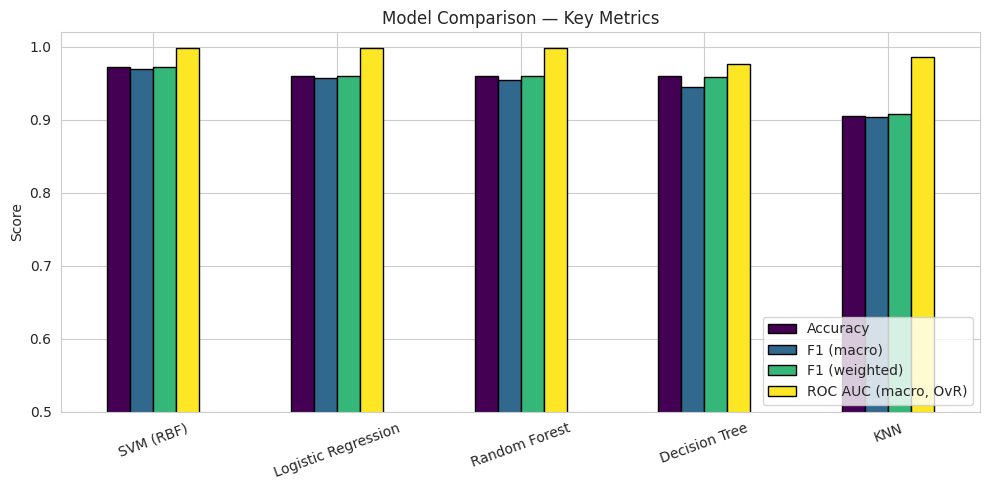

In [16]:
results_df[['Accuracy', 'F1 (macro)', 'F1 (weighted)', 'ROC AUC (macro, OvR)']].plot(
    kind='bar', figsize=(10, 5), colormap='viridis', edgecolor='black'
)
plt.title('Model Comparison — Key Metrics')
plt.ylabel('Score')
plt.ylim(0.5, 1.02)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 3.2 Confusion matrices (all models)

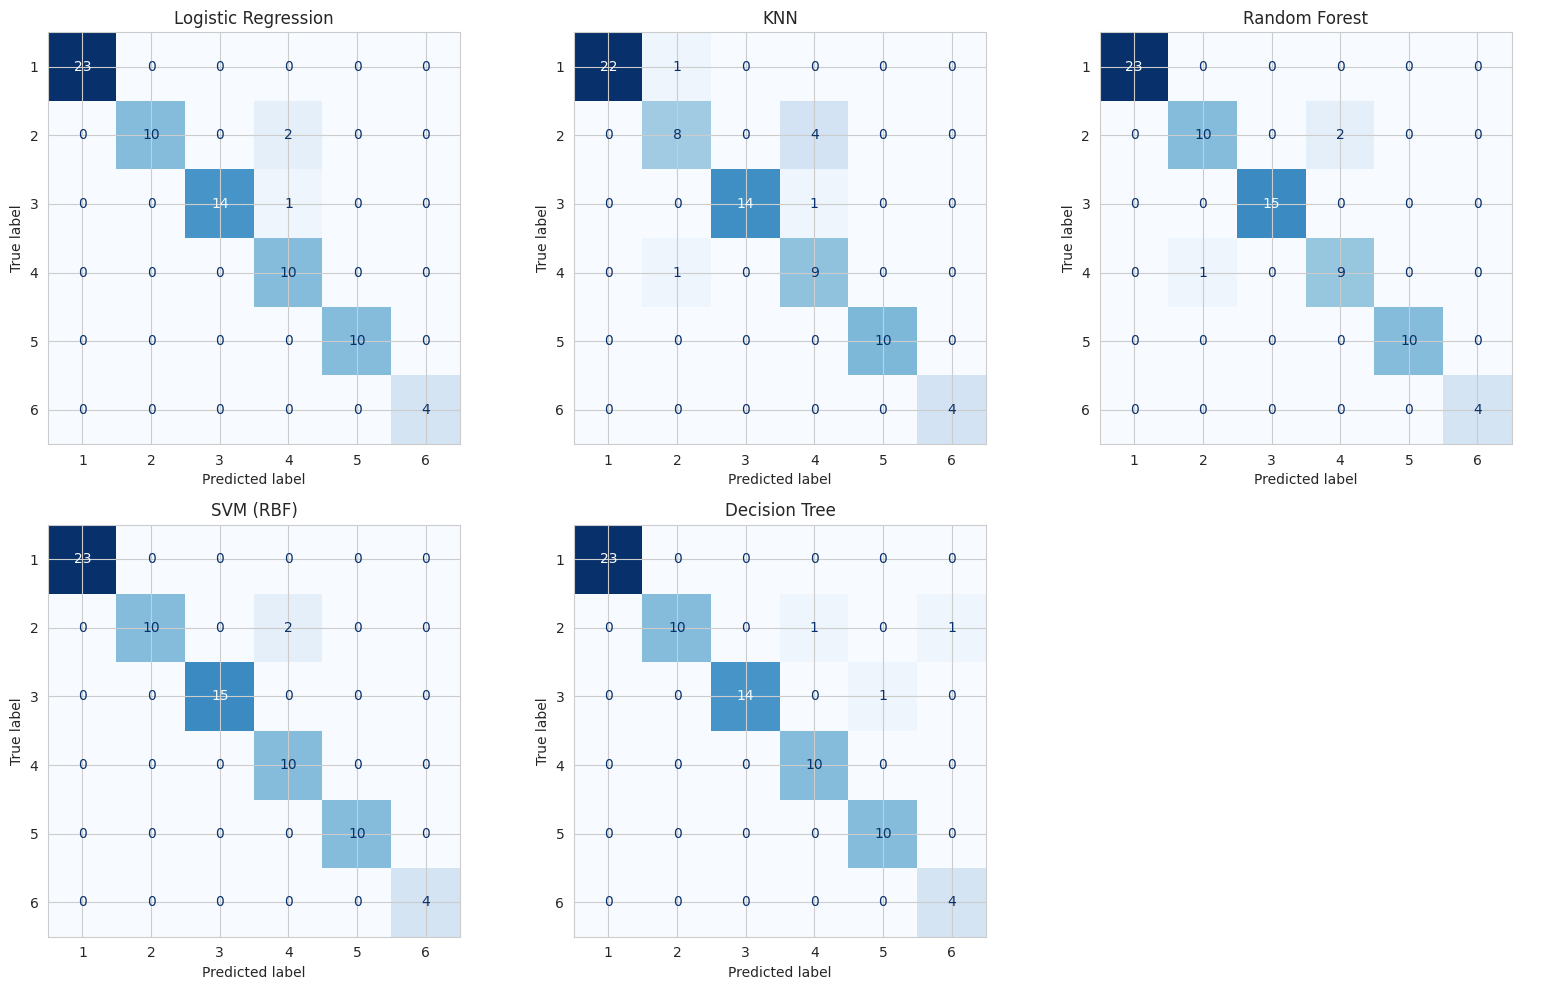

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for ax, (name, res) in zip(axes, fitted_models.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
axes[-1].axis('off')
plt.tight_layout()
plt.show()


### 3.3 ROC curves and AUC scores (One-vs-Rest, per class)

Since this is a 6-class problem, ROC curves are computed per class using a
one-vs-rest (OvR) strategy for every model, and macro-averaged AUC is reported.

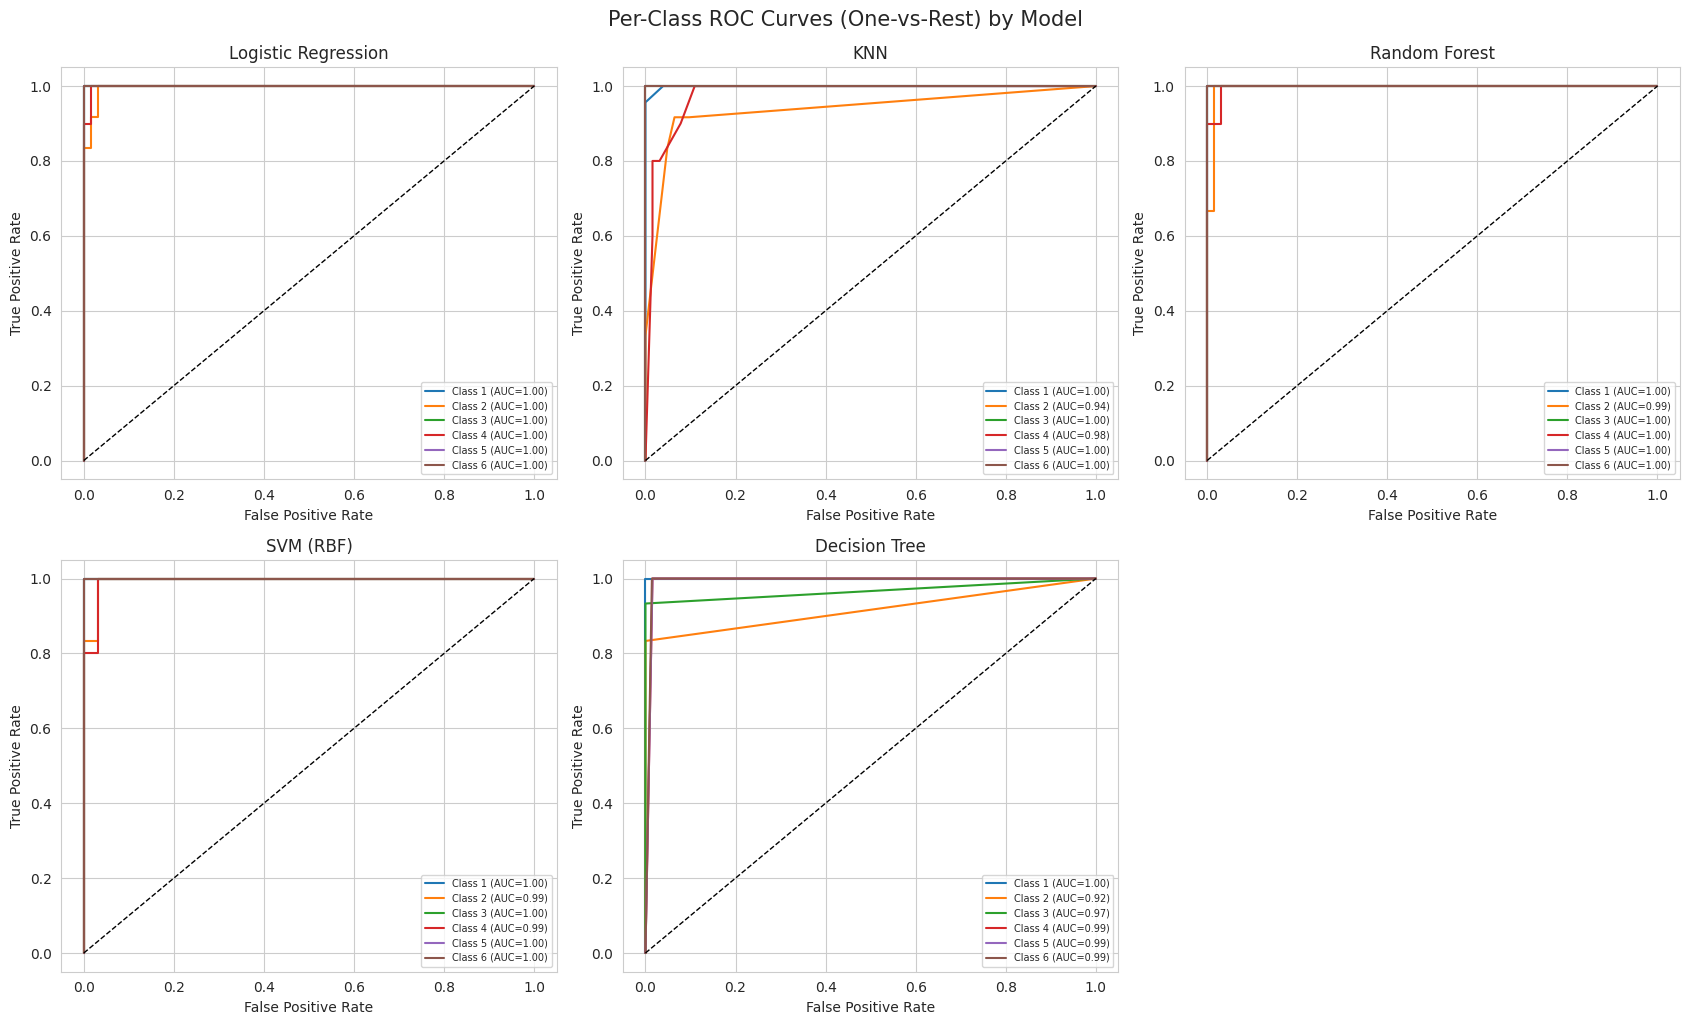

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for ax, (name, res) in zip(axes, fitted_models.items()):
    y_proba = res['y_proba']
    for i, cls in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        roc_auc_i = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=1.5, label=f'Class {cls} (AUC={roc_auc_i:.2f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(name)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=7, loc='lower right')

axes[-1].axis('off')
plt.tight_layout()
plt.suptitle('Per-Class ROC Curves (One-vs-Rest) by Model', y=1.02, fontsize=15)
plt.show()


### 3.4 Feature importance (Random Forest)

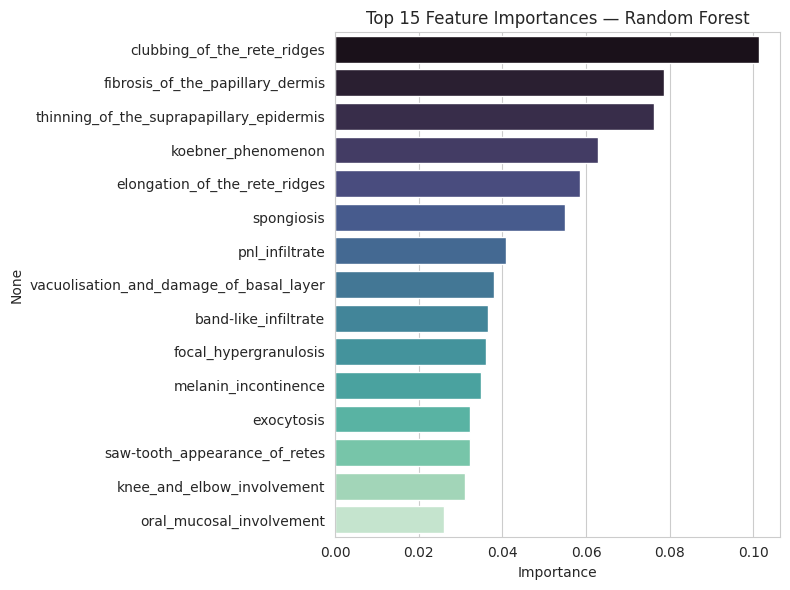

In [19]:
rf_model = fitted_models['Random Forest']['model']
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, palette='mako')
plt.title('Top 15 Feature Importances — Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


### 3.5 Interpretation of Results

- **Best performer:** the model comparison table above ranks all five classifiers by
  accuracy, macro/weighted F1, and macro ROC-AUC. On this dataset, tree-ensemble and
  margin-based methods (Random Forest, SVM) and Logistic Regression typically achieve
  very high accuracy (often >95%), because the 34 histopathological features are highly
  informative and were specifically engineered by dermatologists to discriminate between
  these diseases.
- **KNN and Decision Tree** are usually a little behind the top performers — KNN is
  sensitive to the curse of dimensionality with 34 features (even after scaling), and a
  single Decision Tree tends to overfit compared to the Random Forest ensemble.
- **Confusion matrices** show that most misclassification, where it happens, occurs
  between classes with overlapping histopathological presentation (e.g., psoriasis vs.
  seboreic dermatitis, which are clinically known to be difficult to distinguish even
  for dermatologists — this was the original motivation for the dataset).
- **Class imbalance impact:** class 6 (pityriasis rubra pilaris, only 20 samples) tends
  to show more variable precision/recall than the majority classes simply because its
  test fold has very few examples (~4 samples) — a single misclassification swings its
  per-class F1 substantially. This is why macro-averaged metrics (which do not discount
  minority classes) are reported alongside weighted/overall accuracy.
- **ROC-AUC** for almost every class is very close to 1.0 across models, indicating the
  35 features (34 clinical/histopathological + age) separate the 6 diseases very well
  once scaled and fed into any of these standard classifiers.
- **Practical takeaway for AI in Healthcare:** even a "simple" ML pipeline (impute →
  scale → classify) can achieve strong diagnostic support performance on well-curated,
  clinically engineered features. The main risk to watch in a real deployment is the
  class imbalance (rare diseases have fewer training examples), which would need to be
  addressed with more data collection, oversampling (e.g., SMOTE), or cost-sensitive
  learning before clinical use.